In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Output/netflix_cleaned.csv")
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Dataset loaded successfully!
Rows: 8790
Columns: 10


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [5]:
# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

# Remove rows where the date is missing
trend_df = df.dropna(subset=["date_added"]).copy()

# Extract the year
trend_df["year_added"] = trend_df["date_added"].dt.year

# Count titles added each year
yearly_data = (
    trend_df.groupby("year_added")
    .size()
    .reset_index(name="title_count")
)

print("Yearly Netflix content additions:")
display(yearly_data)

Yearly Netflix content additions:


,year_added,title_count
0,2008,2
1,2009,2
2,2010,1
3,2011,13
4,2012,3
5,2013,11
6,2014,24
7,2015,82
8,2016,426
9,2017,1185


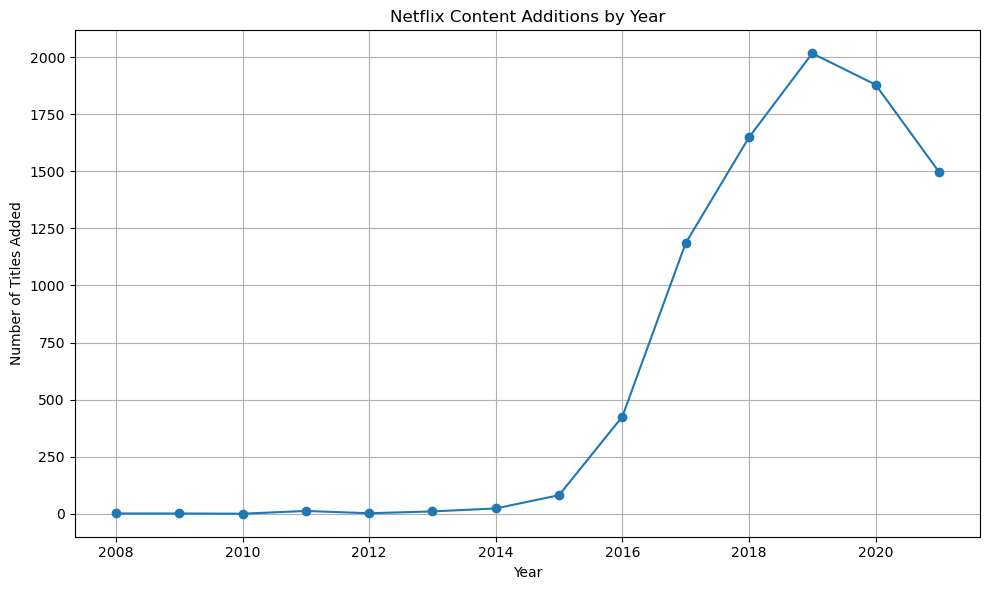

In [6]:
plt.figure(figsize=(10, 6))

plt.plot(
    yearly_data["year_added"],
    yearly_data["title_count"],
    marker="o"
)
plt.title("Netflix Content Additions by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")

plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Prepare input and output variables
X = yearly_data[["year_added"]]
y = yearly_data["title_count"]

# Train the model
model = LinearRegression()
model.fit(X, y)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [8]:
# Identify the last year in the dataset
last_year = int(yearly_data["year_added"].max())

# Create the next three years
future_years = pd.DataFrame({
    "year_added": [last_year + 1, last_year + 2, last_year + 3]
})

# Predict title additions
future_years["predicted_titles"] = model.predict(
    future_years[["year_added"]]
)

# Round predictions to whole numbers
future_years["predicted_titles"] = (
    future_years["predicted_titles"]
    .round()
    .astype(int)
    .clip(lower=0)
)

print("Predicted Netflix Content Additions:")
display(future_years)

Predicted Netflix Content Additions:


,year_added,predicted_titles
0,2022,1895
1,2023,2064
2,2024,2233


In [9]:
# Predict historical values
historical_predictions = model.predict(X)

mae = mean_absolute_error(y, historical_predictions)
r2 = r2_score(y, historical_predictions)

print("Model Evaluation")
print("----------------")
print("Mean Absolute Error:", round(mae, 2))
print("R-squared Score:", round(r2, 3))

Model Evaluation
----------------
Mean Absolute Error: 346.07
R-squared Score: 0.753


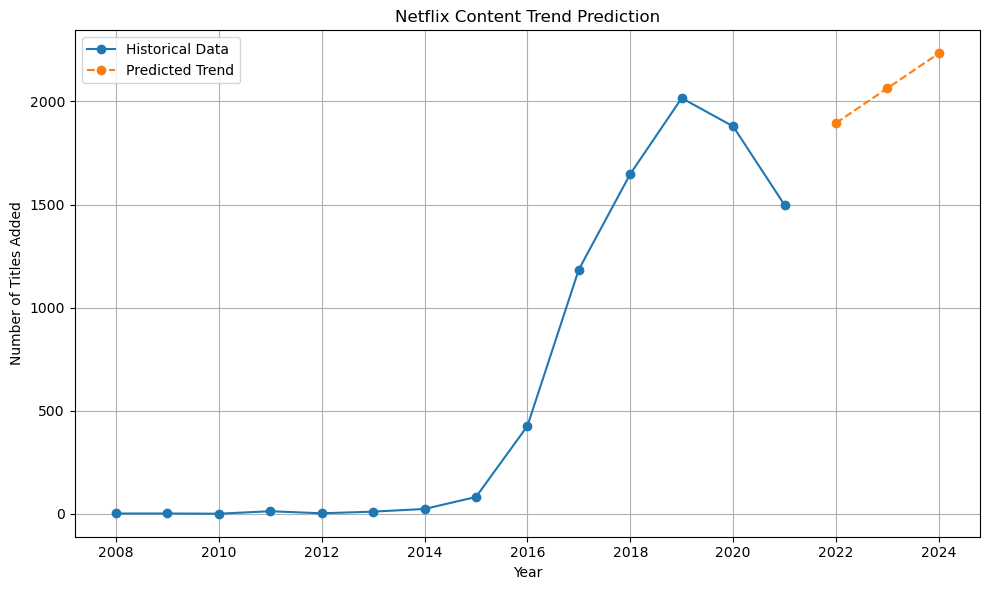

In [10]:
plt.figure(figsize=(10, 6))

# Historical data
plt.plot(
    yearly_data["year_added"],
    yearly_data["title_count"],
    marker="o",
    label="Historical Data"
)

# Future predictions
plt.plot(
    future_years["year_added"],
    future_years["predicted_titles"],
    marker="o",
    linestyle="--",
    label="Predicted Trend"
)

plt.title("Netflix Content Trend Prediction")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

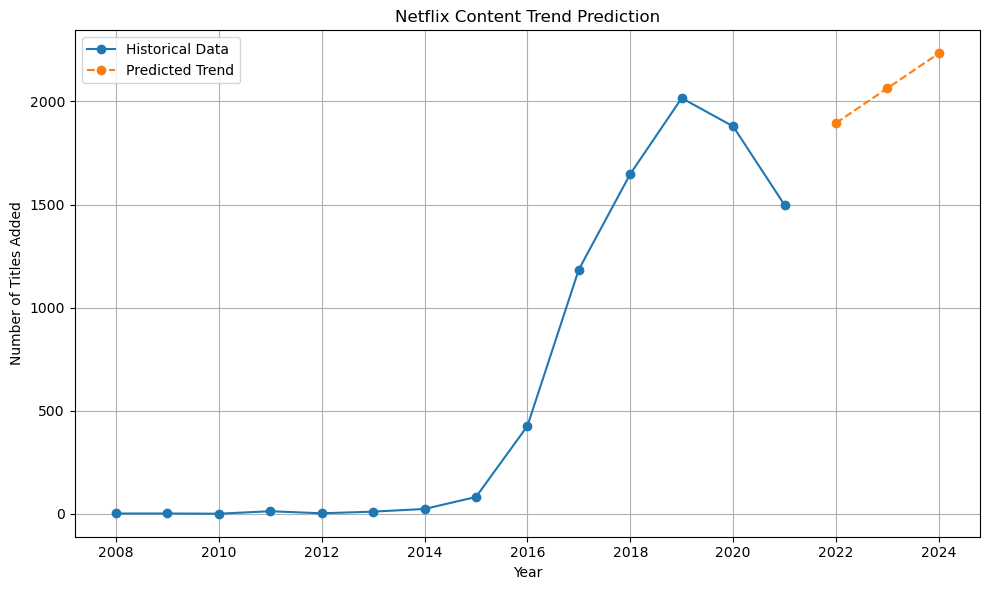

Trend prediction graph saved successfully!


In [11]:
import os

os.makedirs("Graphs", exist_ok=True)

plt.figure(figsize=(10, 6))

plt.plot(
    yearly_data["year_added"],
    yearly_data["title_count"],
    marker="o",
    label="Historical Data"
)

plt.plot(
    future_years["year_added"],
    future_years["predicted_titles"],
    marker="o",
    linestyle="--",
    label="Predicted Trend"
)

plt.title("Netflix Content Trend Prediction")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "Graphs/netflix_trend_prediction.png",
    bbox_inches="tight"
)

plt.show()

print("Trend prediction graph saved successfully!")

# Trend Prediction Analysis — Conclusion

### Objective

To analyze historical Netflix content additions and estimate future trends using Linear Regression.

### Methodology

1. Loaded the cleaned Netflix dataset.
2. Converted the date-added column into a datetime format.
3. Counted titles added in each year.
4. Visualized historical content additions.
5. Trained a Linear Regression model.
6. Generated estimates for the next three years.
7. Evaluated the model using MAE and R-squared.

### Conclusion

The analysis demonstrates how historical data can be used to identify trends and generate preliminary forecasts. Linear Regression provides a simple baseline for estimating future Netflix content additions. However, these estimates depend on historical patterns and should not be interpreted as guaranteed future values.